<a href="https://colab.research.google.com/github/Ye-sys/Nxt-trendzz/blob/main/Support_Ticket_Priority_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("support_ticket_priority_200_records.csv")

print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

print("\nMissing values:")
print(df.isnull().sum())


(200, 16)

Column names:
['ticket_id', 'users_affected', 'service_unavailable', 'login_failure', 'core_feature_broken', 'business_impact', 'issue_type', 'environment', 'customer_tier', 'is_blocking_work', 'error_rate_percent', 'response_time_ms', 'reproducible', 'recent_release', 'sla_hours_remaining', 'priority']


,ticket_id,users_affected,service_unavailable,login_failure,core_feature_broken,business_impact,issue_type,environment,customer_tier,is_blocking_work,error_rate_percent,response_time_ms,reproducible,recent_release,sla_hours_remaining,priority
0,T001,100,0,0,0,0,Authentication,Production,Standard,0,9.2,4695,0,0,38.1,Low
1,T002,100,0,1,0,1,UI,Production,Standard,1,16.2,3856,1,1,18.2,Medium
2,T003,60,0,0,0,1,UI,Production,Business,0,27.4,388,0,1,32.8,Low
3,T004,60,0,0,0,2,Authentication,Production,Standard,1,11.3,81,0,0,45.7,Medium
4,T005,10,0,1,1,1,Availability,Production,Business,0,1.4,1993,1,0,18.2,Low



Missing values:
ticket_id              0
users_affected         0
service_unavailable    0
login_failure          0
core_feature_broken    0
business_impact        0
issue_type             0
environment            0
customer_tier          0
is_blocking_work       0
error_rate_percent     0
response_time_ms       0
reproducible           0
recent_release         0
sla_hours_remaining    0
priority               0
dtype: int64


In [5]:

X = df.drop(columns=["ticket_id", "priority"])

y = df["priority"]


print("Input shape:", X.shape)
print("Target shape:", y.shape)


Input shape: (200, 14)
Target shape: (200,)


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 160
Testing records: 40


In [7]:
from sklearn.preprocessing import OneHotEncoder

categorical_columns = [
    "issue_type",
    "environment",
    "customer_tier"
]

encoder = OneHotEncoder(handle_unknown="ignore")

X_train_cat = encoder.fit_transform(
    X_train[categorical_columns]
).toarray()

X_test_cat = encoder.transform(
    X_test[categorical_columns]
).toarray()

print("Encoded training shape:", X_train_cat.shape)
print("Encoded testing shape:", X_test_cat.shape)

Encoded training shape: (160, 13)
Encoded testing shape: (40, 13)


In [8]:
from sklearn.preprocessing import StandardScaler

numerical_columns = [
    col for col in X.columns
    if col not in categorical_columns
]

scaler = StandardScaler()

X_train_num = scaler.fit_transform(
    X_train[numerical_columns]
)

X_test_num = scaler.transform(
    X_test[numerical_columns]
)

print("Numerical training shape:", X_train_num.shape)
print("First three scaled rows:")
print(X_train_num[:3])

Numerical training shape: (160, 11)
First three scaled rows:
[[-0.49022388 -0.65465367 -0.56772709 -0.6352234  -0.06917145 -0.82717019
  -0.41865615 -1.17397511  0.60623541 -0.49021432 -0.78938778]
 [-0.31310788  1.52752523 -0.56772709 -0.6352234  -0.06917145 -0.82717019
   0.7747919   1.00719315 -1.64952424 -0.49021432 -1.14373422]
 [-0.80017689 -0.65465367 -0.56772709 -0.6352234   1.31425748  1.20894105
   1.62105507  1.06286225  0.60623541 -0.49021432  0.78271259]]


In [9]:
import numpy as np

X_train_processed = np.concatenate(
    [X_train_num, X_train_cat],
    axis=1
)

X_test_processed = np.concatenate(
    [X_test_num, X_test_cat],
    axis=1
)

print("Final training shape:", X_train_processed.shape)
print("Final testing shape:", X_test_processed.shape)

Final training shape: (160, 24)
Final testing shape: (40, 24)


In [11]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Class order:", label_encoder.classes_)
print("Encoded training labels:", y_train_encoded[:10])

import numpy as np

input_size = X_train_processed.shape[1]

hidden_size = 4


output_size = len(label_encoder.classes_)

rng = np.random.default_rng(42)

W1 = rng.normal(
    0, np.sqrt(2 / input_size),
    size=(input_size, hidden_size)
)
b1 = np.zeros((1, hidden_size))

W2 = rng.normal(
    0, np.sqrt(2 / hidden_size),
    size=(hidden_size, output_size)
)
b2 = np.zeros((1, output_size))

print("Input size:", input_size)
print("Hidden size:", hidden_size)
print("Output size:", output_size)

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)
print("Priority class order:", label_encoder.classes_)

Class order: ['High' 'Low' 'Medium']
Encoded training labels: [1 2 2 1 2 0 2 2 2 0]
Input size: 24
Hidden size: 4
Output size: 3
W1 shape: (24, 4)
b1 shape: (1, 4)
W2 shape: (4, 3)
b2 shape: (1, 3)
Priority class order: ['High' 'Low' 'Medium']


In [12]:

def relu(z):
    return np.maximum(0, z)


def softmax(z):
    # Improve numerical stability
    z = z - np.max(z, axis=1, keepdims=True)

    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


def forward_propagation(X, W1, b1, W2, b2):
    # Hidden layer
    z1 = X @ W1 + b1
    a1 = relu(z1)

    # Output layer
    z2 = a1 @ W2 + b2
    probabilities = softmax(z2)

    return z1, a1, z2, probabilities


z1, a1, z2, probabilities = forward_propagation(
    X_train_processed, W1, b1, W2, b2
)

print("Input shape:", X_train_processed.shape)
print("Hidden layer shape:", a1.shape)
print("Output shape:", probabilities.shape)

print(probabilities[0])

print(probabilities[0].sum())


Input shape: (160, 24)
Hidden layer shape: (160, 4)
Output shape: (160, 3)
[0.28804389 0.30716981 0.4047863 ]
1.0000000000000002


In [13]:


weight = 2.0

learning_rate = 0.1


gradient = 2 * weight

new_weight = weight - learning_rate * gradient

print("Initial weight:", weight)
print("Gradient:", gradient)
print("Updated weight:", new_weight)
print("Initial loss:", weight ** 2)
print("Updated loss:", new_weight ** 2)


Initial weight: 2.0
Gradient: 4.0
Updated weight: 1.6
Initial loss: 4.0
Updated loss: 2.5600000000000005


In [14]:


m = X_train_processed.shape[0]


num_classes = len(label_encoder.classes_)
y_one_hot = np.eye(num_classes)[y_train_encoded]

dZ2 = (probabilities - y_one_hot) / m


dW2 = a1.T @ dZ2
db2 = np.sum(dZ2, axis=0, keepdims=True)


dA1 = dZ2 @ W2.T

dZ1 = dA1 * (z1 > 0)


dW1 = X_train_processed.T @ dZ1
db1 = np.sum(dZ1, axis=0, keepdims=True)

print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)
print("dW2 shape:", dW2.shape)
print("db2 shape:", db2.shape)


dW1 shape: (24, 4)
db1 shape: (1, 4)
dW2 shape: (4, 3)
db2 shape: (1, 3)


In [15]:



learning_rate = 0.01


W1 -= learning_rate * dW1
b1 -= learning_rate * db1


W2 -= learning_rate * dW2
b2 -= learning_rate * db2

print("Weights and biases updated successfully!")
print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)


Weights and biases updated successfully!
W1 shape: (24, 4)
b1 shape: (1, 4)
W2 shape: (4, 3)
b2 shape: (1, 3)


In [16]:


learning_rate = 0.01
epochs = 500

m = X_train_processed.shape[0]
num_classes = len(label_encoder.classes_)

y_one_hot = np.eye(num_classes)[y_train_encoded]

loss_history = []

for epoch in range(epochs):

    z1, a1, z2, probabilities = forward_propagation(
        X_train_processed, W1, b1, W2, b2
    )

    correct_probs = probabilities[
        np.arange(m), y_train_encoded
    ]
    correct_probs = np.clip(correct_probs, 1e-12, 1.0)

    loss = -np.mean(np.log(correct_probs))
    loss_history.append(loss)


    dZ2 = (probabilities - y_one_hot) / m
    dW2 = a1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (z1 > 0)

    dW1 = X_train_processed.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)


    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}, Loss: {loss:.4f}")

print("\nTraining completed!")


Epoch 50, Loss: 1.0938
Epoch 100, Loss: 1.0294
Epoch 150, Loss: 0.9830
Epoch 200, Loss: 0.9428
Epoch 250, Loss: 0.9080
Epoch 300, Loss: 0.8753
Epoch 350, Loss: 0.8430
Epoch 400, Loss: 0.8110
Epoch 450, Loss: 0.7763
Epoch 500, Loss: 0.7433

Training completed!


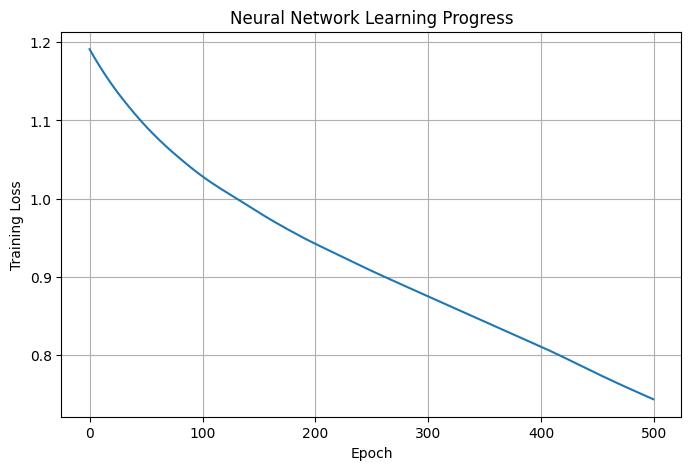

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Neural Network Learning Progress")
plt.grid(True)
plt.show()


In [19]:

from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


_, _, _, test_probabilities = forward_propagation(
    X_test_processed, W1, b1, W2, b2
)


y_test_pred_encoded = np.argmax(test_probabilities, axis=1)


y_test_pred = label_encoder.inverse_transform(y_test_pred_encoded)


accuracy = accuracy_score(y_test, y_test_pred)

print(f"Test Accuracy: {accuracy:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))


cm = confusion_matrix(
    y_test, y_test_pred, labels=label_encoder.classes_
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)



Test Accuracy: 47.50%

Classification Report:
              precision    recall  f1-score   support

        High       0.50      0.40      0.44        10
         Low       0.00      0.00      0.00        12
      Medium       0.48      0.83      0.61        18

    accuracy                           0.47        40
   macro avg       0.33      0.41      0.35        40
weighted avg       0.34      0.47      0.39        40



In [20]:
print("Class order:", label_encoder.classes_)
print("Confusion matrix:")
print(cm)

Class order: ['High' 'Low' 'Medium']
Confusion matrix:
[[ 4  1  5]
 [ 1  0 11]
 [ 3  0 15]]


In [21]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train_processed, y_train_encoded)

baseline_predictions = baseline.predict(X_test_processed)

baseline_accuracy = accuracy_score(
    y_test_encoded, baseline_predictions
)

print(f"Baseline accuracy: {baseline_accuracy:.2%}")
print("\nBaseline classification report:")
print(
    classification_report(
        y_test_encoded,
        baseline_predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


Baseline accuracy: 45.00%

Baseline classification report:
              precision    recall  f1-score   support

        High       0.00      0.00      0.00        10
         Low       0.00      0.00      0.00        12
      Medium       0.45      1.00      0.62        18

    accuracy                           0.45        40
   macro avg       0.15      0.33      0.21        40
weighted avg       0.20      0.45      0.28        40



Input shape: (8, 3)
Target shape: (8, 1)

W1 shape: (3, 4)
b1 shape: (1, 4)
W2 shape: (4, 1)
b2 shape: (1, 1)
Epoch 500, Loss: 0.124823
Epoch 1000, Loss: 0.047552
Epoch 1500, Loss: 0.026312
Epoch 2000, Loss: 0.017649
Epoch 2500, Loss: 0.013147
Epoch 3000, Loss: 0.010420
Epoch 3500, Loss: 0.008612
Epoch 4000, Loss: 0.007333
Epoch 4500, Loss: 0.006381
Epoch 5000, Loss: 0.005649

Actual labels:
[1 0 1 0 1 0 1 1]

Predicted labels:
[1 0 1 0 1 0 1 1]

Training accuracy: 100.00%


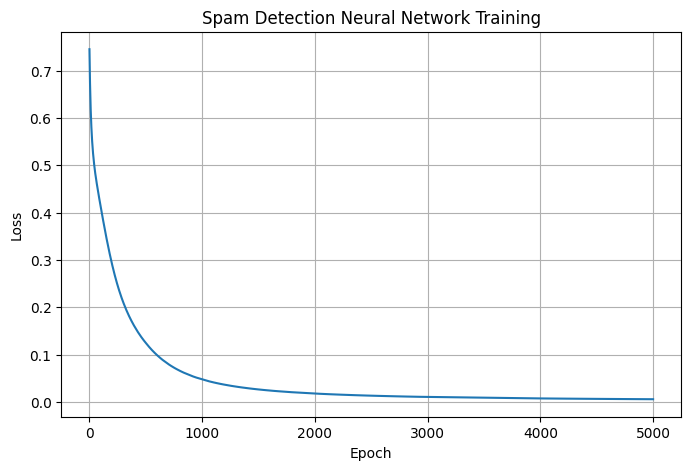


New Email: [[1. 1. 0.]]
Spam probability: 0.9997
Prediction: SPAM


In [1]:

import numpy as np


X = np.array([
    [1, 1, 1],
    [0, 0, 0],
    [1, 0, 1],
    [0, 1, 0],
    [1, 1, 0],
    [0, 0, 1],
    [1, 1, 1],
    [0, 1, 1]
], dtype=float)



y = np.array([
    [1],
    [0],
    [1],
    [0],
    [1],
    [0],
    [1],
    [1]
], dtype=float)

print("Input shape:", X.shape)
print("Target shape:", y.shape)



input_size = 3
hidden_size = 4
output_size = 1

rng = np.random.default_rng(42)

W1 = rng.normal(
    0, np.sqrt(2 / input_size),
    size=(input_size, hidden_size)
)

b1 = np.zeros((1, hidden_size))

W2 = rng.normal(
    0, np.sqrt(2 / hidden_size),
    size=(hidden_size, output_size)
)

b2 = np.zeros((1, output_size))

print("\nW1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)



def relu(z):
    return np.maximum(0, z)


def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))




def forward_propagation(X, W1, b1, W2, b2):

    # Hidden layer calculation
    z1 = X @ W1 + b1
    a1 = relu(z1)

    # Output layer calculation
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)

    return z1, a1, z2, a2


# ==================================================
# STEP 5: LOSS FUNCTION
# ==================================================

def calculate_loss(y, predictions):

    predictions = np.clip(
        predictions, 1e-12, 1 - 1e-12
    )

    loss = -np.mean(
        y * np.log(predictions)
        + (1 - y) * np.log(1 - predictions)
    )

    return loss


# ==================================================
# STEP 6: TRAIN THE NEURAL NETWORK
# ==================================================

learning_rate = 0.05
epochs = 5000

m = X.shape[0]

loss_history = []

for epoch in range(epochs):

    # Forward propagation
    z1, a1, z2, a2 = forward_propagation(
        X, W1, b1, W2, b2
    )

    # Calculate loss
    loss = calculate_loss(y, a2)
    loss_history.append(loss)

    # Backpropagation: output layer
    dZ2 = (a2 - y) / m

    dW2 = a1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Backpropagation: hidden layer
    dA1 = dZ2 @ W2.T

    dZ1 = dA1 * (z1 > 0)

    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    # Gradient descent: update weights and biases
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    if (epoch + 1) % 500 == 0:
        print(
            f"Epoch {epoch + 1}, Loss: {loss:.6f}"
        )


# ==================================================
# STEP 7: FINAL PREDICTIONS
# ==================================================

_, _, _, final_predictions = forward_propagation(
    X, W1, b1, W2, b2
)

predicted_classes = (
    final_predictions >= 0.5
).astype(int)

print("\nActual labels:")
print(y.astype(int).flatten())

print("\nPredicted labels:")
print(predicted_classes.flatten())

accuracy = np.mean(
    predicted_classes == y
) * 100

print(f"\nTraining accuracy: {accuracy:.2f}%")


# ==================================================
# STEP 8: VISUALIZE TRAINING LOSS
# ==================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Spam Detection Neural Network Training")
plt.grid(True)
plt.show()


# ==================================================
# STEP 9: PREDICT A NEW EMAIL
# ==================================================

new_email = np.array([
    [1, 1, 0]
], dtype=float)

_, _, _, new_probability = forward_propagation(
    new_email, W1, b1, W2, b2
)

if new_probability[0, 0] >= 0.5:
    result = "SPAM"
else:
    result = "NOT SPAM"

print("\nNew Email:", new_email)
print("Spam probability:", f"{new_probability[0, 0]:.4f}")
print("Prediction:", result)
